In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df=pd.read_csv("netflix_titles.csv")
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [4]:
#Dataset Information
print("\n Information about The Data")
df.info()

#Shape of the Data
print("\n Shape of the Data:")
print(df.shape)

#Statistics Information
print("\n Statistics Information:")
df.describe()


 Information about The Data
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB

 Shape of the Data:
(8807, 12)

 Statistics Information:


,release_year
count,8807.000000
mean,2014.180198
std,8.819312
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


In [7]:
#Check Null Values
df.isnull().sum()

,0
show_id,0
type,0
title,0
director,2634
cast,825
country,831
date_added,10
release_year,0
rating,4
duration,3


In [22]:
#change date added format of string to DateTime format safely
df['year_added'] = df['date_added'].dt.year
df['month_added'] = df['date_added'].dt.month_name()
df['day_added'] = df['date_added'].dt.day_name()
print(df[['date_added', 'year_added', 'month_added', 'day_added']].head())

  date_added  year_added month_added day_added
2 2021-09-24        2021   September    Friday
5 2021-09-24        2021   September    Friday
6 2021-09-24        2021   September    Friday
7 2021-09-24        2021   September    Friday
8 2021-09-24        2021   September    Friday


In [21]:
df.dropna(subset="cast",inplace=True)
df.dropna(subset="director",inplace=True)
df.isnull().sum()

,0
show_id,0
type,0
title,0
director,0
cast,0
country,0
date_added,0
release_year,0
rating,0
duration,0


In [23]:
df.dropna(subset="duration",inplace=True)
df['country']=df['country'].fillna("unknown")
df['rating']=df['rating'].fillna(df['rating'].mode()[0])
df.isna().sum()

,0
show_id,0
type,0
title,0
director,0
cast,0
country,0
date_added,0
release_year,0
rating,0
duration,0


In [24]:
print("\n After cleaning The data,The shape was:")
print(df.shape)


 After cleaning The data,The shape was:
(5697, 15)


In [25]:
#Recheck for Null Values
df.isnull().sum()

,0
show_id,0
type,0
title,0
director,0
cast,0
country,0
date_added,0
release_year,0
rating,0
duration,0


In [30]:
df_clean=df.to_csv("netflix_titles_cleaned.csv", index=False)

print("🎉 Success! Your clean dataset has been saved as 'netflix_titles_cleaned.csv'")

🎉 Success! Your clean dataset has been saved as 'netflix_titles_cleaned.csv'


In [32]:
df_clean = pd.read_csv("netflix_titles_cleaned.csv")
df_clean.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,year_added,month_added,day_added
0,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,2021,September,Friday
1,s6,TV Show,Midnight Mass,Mike Flanagan,"Kate Siegel, Zach Gilford, Hamish Linklater, H...",unknown,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",The arrival of a charismatic young priest brin...,2021,September,Friday
2,s7,Movie,My Little Pony: A New Generation,"Robert Cullen, José Luis Ucha","Vanessa Hudgens, Kimiko Glenn, James Marsden, ...",unknown,2021-09-24,2021,PG,91 min,Children & Family Movies,Equestria's divided. But a bright-eyed hero be...,2021,September,Friday
3,s8,Movie,Sankofa,Haile Gerima,"Kofi Ghanaba, Oyafunmike Ogunlano, Alexandra D...","United States, Ghana, Burkina Faso, United Kin...",2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies","On a photo shoot in Ghana, an American model s...",2021,September,Friday
4,s9,TV Show,The Great British Baking Show,Andy Devonshire,"Mel Giedroyc, Sue Perkins, Mary Berry, Paul Ho...",United Kingdom,2021-09-24,2021,TV-14,9 Seasons,"British TV Shows, Reality TV",A talented batch of amateur bakers face off in...,2021,September,Friday


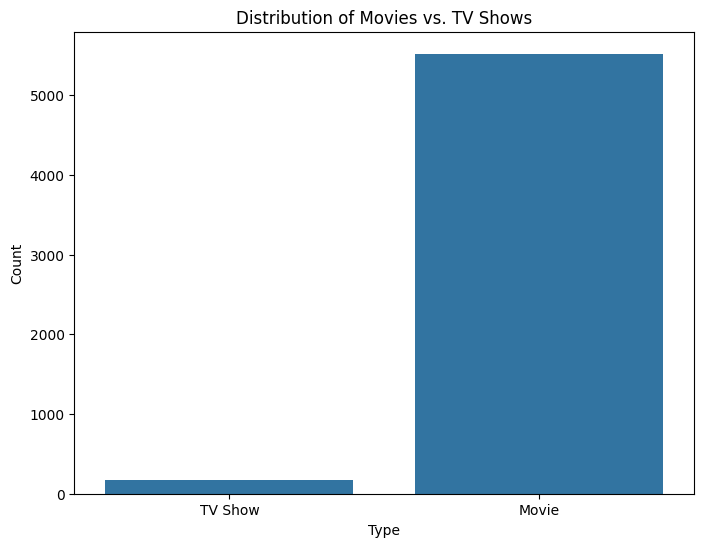

In [34]:
#1)current ratio of Movies vs. TV Shows on the platform
df_clean.groupby('type')['release_year'].count()
plt.figure(figsize=(8, 6))
sns.countplot(x='type', data=df_clean)
plt.title('Distribution of Movies vs. TV Shows')
plt.xlabel('Type')
plt.ylabel('Count')
plt.show()

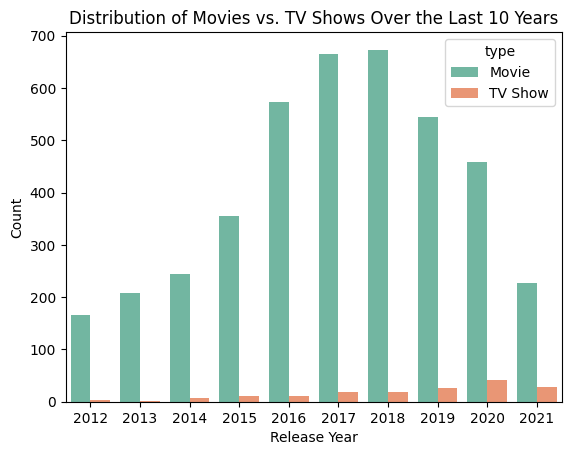

In [41]:
#2)how has this mix changed over the last 10 years
df_last_10_years =df[df['release_year'] >= 2012]
sns.countplot(data=df_last_10_years,x='release_year', hue='type', palette='Set2')
plt.title('Distribution of Movies vs. TV Shows Over the Last 10 Years')
plt.xlabel('Release Year')
plt.ylabel('Count')
plt.show()

/tmp/ipykernel_2662/2183205518.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


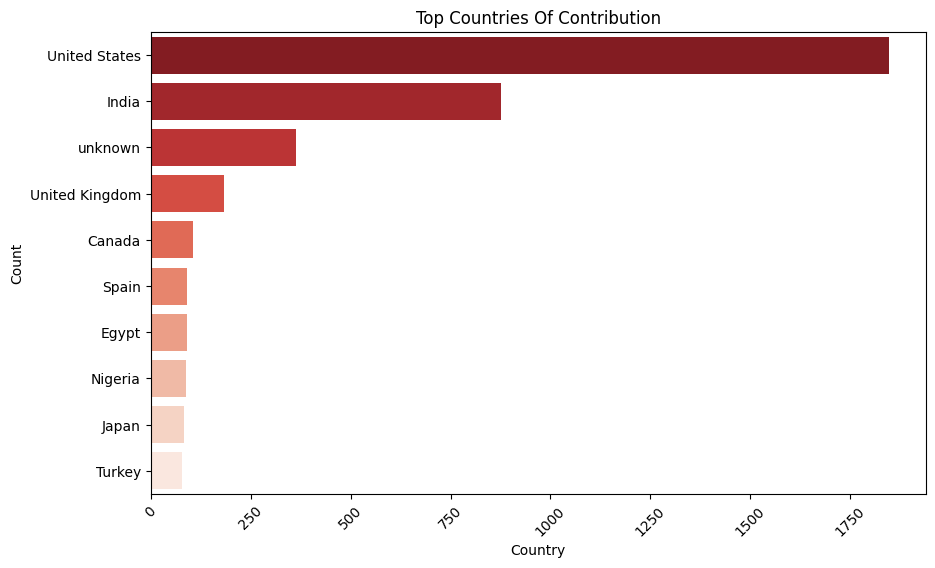

In [49]:
#3)Which countries are the top contributors to the Netflix
plt.figure(figsize=(10, 6))
sns.countplot(
    y='country',
    data=df,
    order=df['country'].value_counts().index[:10],
    palette='Reds_r'
)
plt.title("Top Countries Of Contribution")
plt.xlabel("Country")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

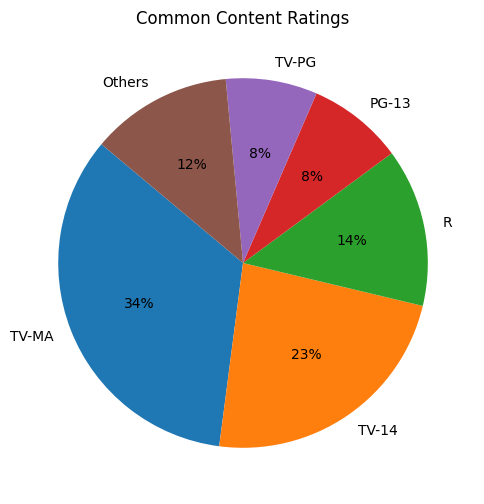

In [70]:
#4)What are the most common content ratings and who is the primary target audience
rating_counts = df['rating'].value_counts()
top_5_ratings = rating_counts.head(5)
others_sum = rating_counts.iloc[5:].sum()
final_counts = pd.concat([top_5_ratings, pd.Series({'Others': others_sum})])
plt.figure(figsize=(10, 6))
plt.pie(
    final_counts,
    labels=final_counts.index,
    autopct='%1.0f%%',
    startangle=140
)
plt.title('Common Content Ratings')
plt.show()

/tmp/ipykernel_2662/173963419.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax=sns.countplot(


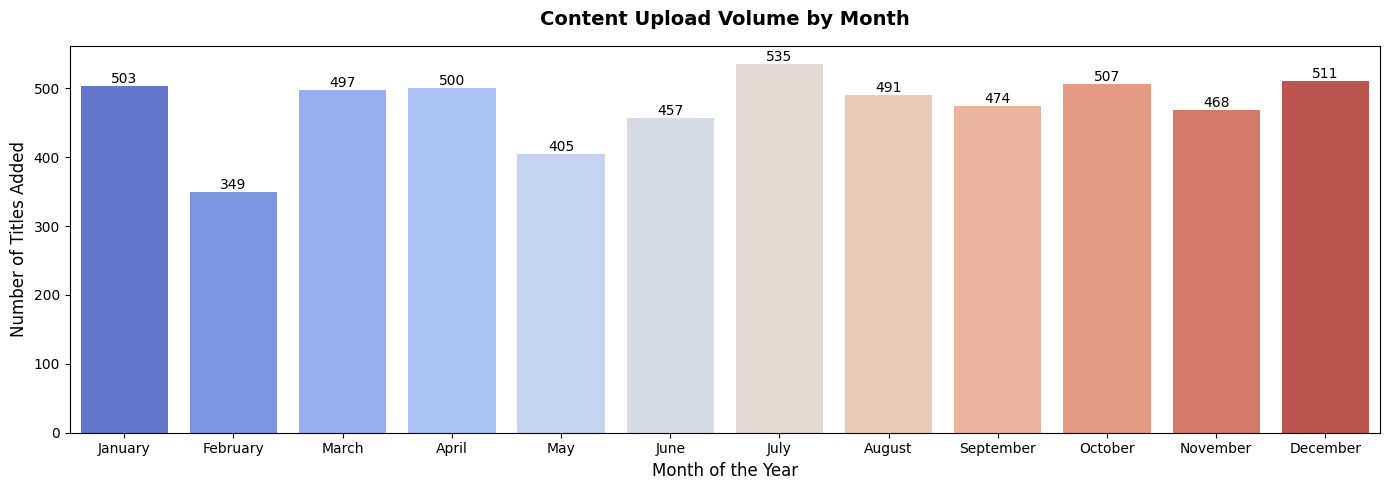

In [75]:
#5)In which month or season does the platform add the highest volume of content
month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']
df['month_name'] = df['date_added'].dt.month_name()
plt.figure(figsize=(14, 5))
ax=sns.countplot(
    x='month_name',
    data=df.dropna(subset=['month_name']),
    order=month_order,
    palette='coolwarm'
)
plt.title('Content Upload Volume by Month', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Month of the Year', fontsize=12)
plt.ylabel('Number of Titles Added', fontsize=12)
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.show()


/tmp/ipykernel_2662/26029463.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=genre_counts.index, y=genre_counts.values, palette="tab10")


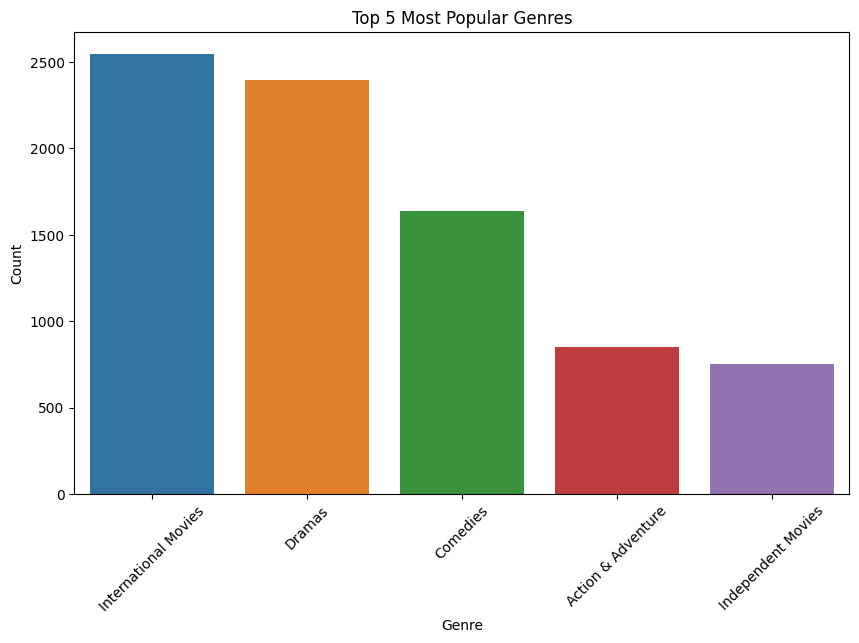

In [77]:
#6)top 5 most popular genres on the platform?
df['listed_in'] = df['listed_in'].str.split(', ')
df = df.explode('listed_in')
genre_counts = df['listed_in'].value_counts().head(5)
plt.figure(figsize=(10, 6))
sns.barplot(x=genre_counts.index, y=genre_counts.values, palette="tab10")
plt.title('Top 5 Most Popular Genres')
plt.xlabel('Genre')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()